# Ernst van letselongevallen: wat valt op?

## Definitie
Dit notebook gebruikt het kaartbestand van Statbel. Een **ernstig ongeval** heeft bronklasse `1` (met doden), `2` (dodelijk gewonden) of `3` (zwaargewonden); klasse `4` heeft lichtgewonden. Het percentage is het aandeel onder geregistreerde letselongevallen, geen kans per rit. De kaartbron van 2024 telt 35.916 registraties, 16 minder dan de algemene ongevalstabel. Alle nationale vergelijkingen hieronder gebruiken uitsluitend de kaartbron.

In [1]:
from pathlib import Path
import pandas as pd,numpy as np,matplotlib.pyplot as plt
from IPython.display import display
B=Path.cwd()
if not (B/'figures').exists():B=B/'analysis_notebooks'
F=B/'figures';T=B/'tables';G=B.parent/'data/gold'
d=pd.read_parquet(G/'accident_map/accident_map.parquet')
d['ernstig']=d.CD_CLASS_ACCIDENTS.isin(['1','2','3']);x=d[d.analysis_year==2024].copy()
def tab(group,min_n=100):
 z=x.groupby(group,dropna=False).agg(ongevallen=('_record_id','count'),ernstig=('ernstig','sum'))
 z['ernst_pct']=100*z.ernstig/z.ongevallen
 return z[z.ongevallen>=min_n].sort_values('ernst_pct',ascending=False)
def plot(z,title,name):
 fig,ax=plt.subplots(figsize=(11,6));z.ernst_pct.sort_values().plot.barh(ax=ax,color='#D76B32');ax.set(title=title,xlabel='Ernstige ongevallen / alle letselongevallen (%)',ylabel='');fig.tight_layout();fig.savefig(F/(name+'.png'),dpi=200,bbox_inches='tight');fig.savefig(F/(name+'.svg'),bbox_inches='tight');plt.show();plt.close(fig)


## 1. Verandert de ernstverdeling door de jaren?
Controleer teller, noemer en aandeel. Een verschuiving in registratie of samenstelling kan het aandeel beïnvloeden.

,ongevallen,ernstig,ernst_pct
analysis_year,,,
2017,38025,3975,10.45
2018,38453,3841,9.99
2019,37719,3847,10.20
2020,30251,3202,10.58
2021,34660,3338,9.63
2022,37650,3621,9.62
2023,36858,3524,9.56
2024,35916,3184,8.87


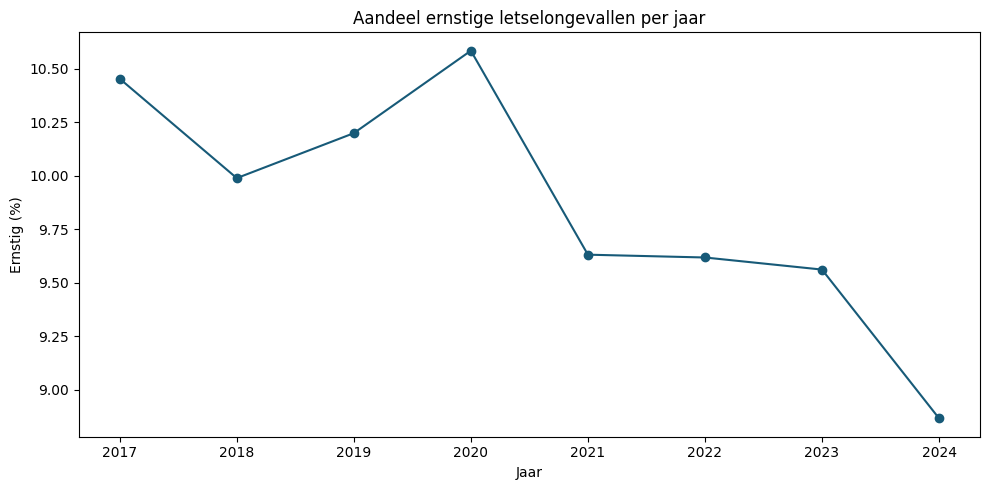

In [2]:
annual=d.groupby('analysis_year').agg(ongevallen=('_record_id','count'),ernstig=('ernstig','sum'));annual['ernst_pct']=100*annual.ernstig/annual.ongevallen
annual.to_csv(T/'ernst_per_jaar_kaart.csv');display(annual.round(2))
fig,ax=plt.subplots(figsize=(10,5));annual.ernst_pct.plot(ax=ax,marker='o',color='#175A78');ax.set(title='Aandeel ernstige letselongevallen per jaar',ylabel='Ernstig (%)',xlabel='Jaar');fig.tight_layout();fig.savefig(F/'18_ernst_trend.png',dpi=200,bbox_inches='tight');fig.savefig(F/'18_ernst_trend.svg',bbox_inches='tight');plt.show();plt.close(fig)


## 2. Botsingstype: een val of een aanrijding?
Sommige typen hebben weinig ongevallen maar een hoger aandeel ernstige gevolgen. De figuur toont alleen typen met minstens 100 registraties.

,ongevallen,ernstig,ernst_pct
TX_COLLISION_TYPE_NL,,,
"Eén bestuurder, geen hindernis (incl. val)",2288,331,14.47
Weggebruiker tegen hindernis buiten rijbaan,4070,548,13.46
Weggebruiker tegen hindernis op de rijbaan,732,96,13.11
Tussen 2 bestuurders: Frontale botsing,2627,334,12.71
Met een voetganger,3597,424,11.79
Andere of onbekend,1403,102,7.27
Tss. 2 best.: langs opzij (voor-/achterkant-flank),10321,720,6.98
Geen vermelding van de type aanrijding,2701,168,6.22
Tussen 2 bestuurders: Flank tegen flank,2860,174,6.08


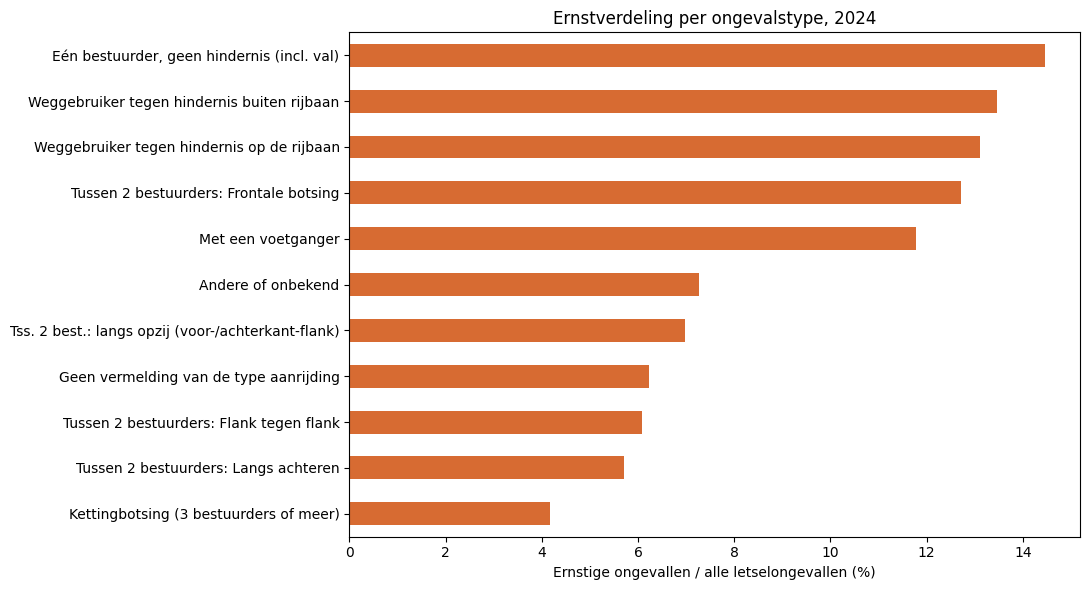

In [3]:
types=tab('TX_COLLISION_TYPE_NL');types.to_csv(T/'ernst_per_botsingstype_2024.csv');display(types.round(2));plot(types,'Ernstverdeling per ongevalstype, 2024','19_ernst_botsingstype')


## 3. Licht en locatieconditie
Onbekend is een aparte categorie. Het verschil tussen dag en onverlichte nacht kan samenhangen met snelheid, tijdstip, type weg of type ongeval. Deze analyse toont verbanden, geen effect van verlichting.

,ongevallen,ernstig,ernst_pct
TX_LIGHT_CONDITION_NL,,,
"Nacht, openb. verlicht. aanw., maar niet ontstoken",465,68,14.62
"Nacht, geen openbare verlichting aanwezig",1027,149,14.51
"Nacht, openbare verlichting aanwezig en ontstoken",6524,676,10.36
Dag,24749,2116,8.55
Dageraad - schemering,1676,119,7.10
Onbekend,1475,56,3.80


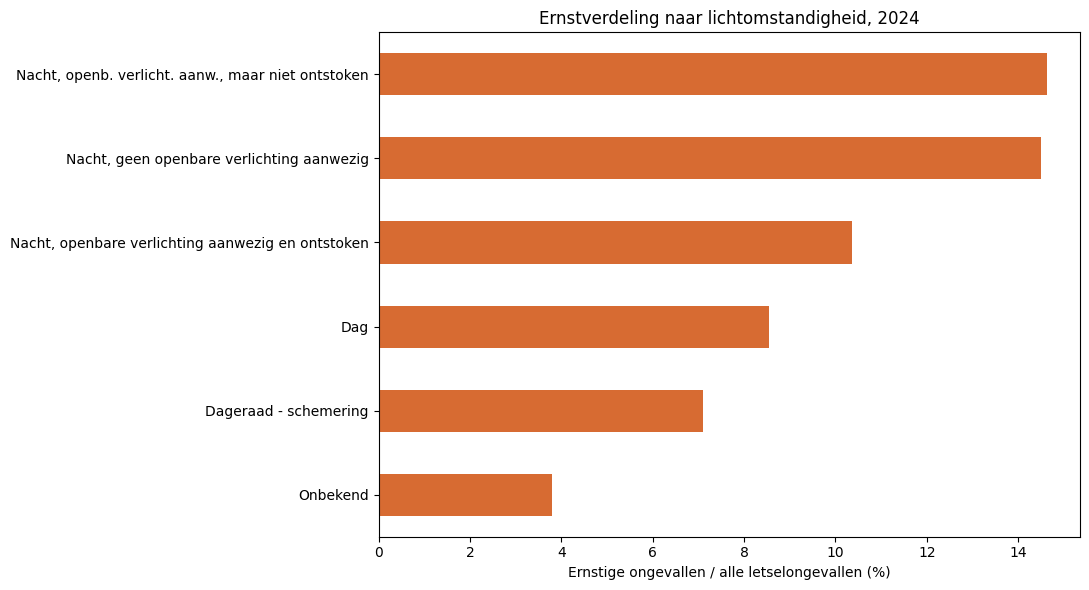

,ongevallen,ernstig,ernst_pct
TX_CROSSWAY_NL,,,
Buiten Kruispunt,24237,2319,9.57
Op Kruispunt,11679,865,7.41


In [4]:
light=tab('TX_LIGHT_CONDITION_NL');light.to_csv(T/'ernst_per_licht_2024.csv');display(light.round(2));plot(light,'Ernstverdeling naar lichtomstandigheid, 2024','20_ernst_licht')
junction=tab('TX_CROSSWAY_NL');junction.to_csv(T/'ernst_per_kruispunt_2024.csv');display(junction.round(2))


## 4. Houdt het nachtverschil stand binnen wegtype en botsingstype?
We vergelijken dag en onverlichte nacht in dezelfde wegtypecategorie. Daarna bekijken we de samenstelling van ongevalstypen. Kleine cellen worden niet als betrouwbare ranglijst behandeld.

In [5]:
choice=['Dag','Nacht, geen openbare verlichting aanwezig'];z=x[x.TX_LIGHT_CONDITION_NL.isin(choice)]
cross=z.groupby(['CD_ROAD_TYPE_NL','TX_LIGHT_CONDITION_NL']).agg(n=('_record_id','count'),ernstig=('ernstig','sum'));cross['ernst_pct']=100*cross.ernstig/cross.n
cross.to_csv(T/'ernst_licht_binnen_wegtype.csv');display(cross.round(2))
mix=pd.crosstab(z.TX_LIGHT_CONDITION_NL,z.TX_COLLISION_TYPE_NL,normalize='index')*100
mix.to_csv(T/'botsingstype_mix_dag_nacht.csv');display(mix.round(1).T.sort_values('Nacht, geen openbare verlichting aanwezig',ascending=False).head(8))


n  ernstig  \
CD_ROAD_TYPE_NL TX_LIGHT_CONDITION_NL                                       
Autosnelweg     Dag                                         1681      138   
                Nacht, geen openbare verlichting aanwezig     81       16   
Gemeenteweg     Dag                                        11697     1039   
                Nacht, geen openbare verlichting aanwezig    534       75   
Gewestweg       Dag                                        11298      933   
                Nacht, geen openbare verlichting aanwezig    404       57   
onbekend        Dag                                           73        6   
                Nacht, geen openbare verlichting aanwezig      8        1   

                                                           ernst_pct  
CD_ROAD_TYPE_NL TX_LIGHT_CONDITION_NL                                 
Autosnelweg     Dag                                             8.21  
                Nacht, geen openbare verlichting aanwezig      19.75  
Gemeenteweg     Dag                                             8.88  
                Nacht, geen openbare verlichting aanwezig      14.04  
Gewestweg       Dag                                             8.26  
                Nacht, geen openbare verlichting aanwezig      14.11  
onbekend        Dag                                             8.22  
                Nacht, geen openbare verlichting aanwezig      12.50

TX_LIGHT_CONDITION_NL,Dag,"Nacht, geen openbare verlichting aanwezig"
TX_COLLISION_TYPE_NL,,
Weggebruiker tegen hindernis buiten rijbaan,8.0,38.7
"Eén bestuurder, geen hindernis (incl. val)",6.0,13.3
Tss. 2 best.: langs opzij (voor-/achterkant-flank),31.9,10.4
Tussen 2 bestuurders: Langs achteren,12.6,7.4
Tussen 2 bestuurders: Frontale botsing,7.5,6.5
Geen vermelding van de type aanrijding,5.8,5.6
Met een voetganger,10.5,5.5
Tussen 2 bestuurders: Flank tegen flank,8.8,4.8


## 5. Waar liggen concentraties van ernstige ongevallen?
Een vast raster van 500 meter toont cellen met minstens 20 gegeocodeerde letselongevallen. De kaartregistraties zonder valide coördinaten blijven in de nationale tabellen, maar zijn niet op de kaart te lokaliseren. Cellen met de meeste ernstige ongevallen worden als **onderzoeksgebieden** genoemd, niet als bewijs voor een lokale oorzaak.

ongevallen  ernstig             gemeente  ernst_pct
gx  gy                                                      
310 429          29        4            Antwerpen       13.8
298 343          47        3              Brussel        6.4
    347          26        3              Brussel       11.5
295 342          25        3  Sint-Jans-Molenbeek       12.0
301 418          20        3            Antwerpen       15.0
305 422          30        2            Antwerpen        6.7
298 338          26        2              Brussel        7.7
295 341          25        2              Brussel        8.0
210 390          23        2                 Gent        8.7
296 344          21        2  Sint-Jans-Molenbeek        9.5
301 347          21        2           Schaarbeek        9.5
298 339          20        2              Brussel       10.0
310 423          42        1            Antwerpen        2.4
    426          37        1            Antwerpen        2.7
298 341          34        1              Brussel        2.9

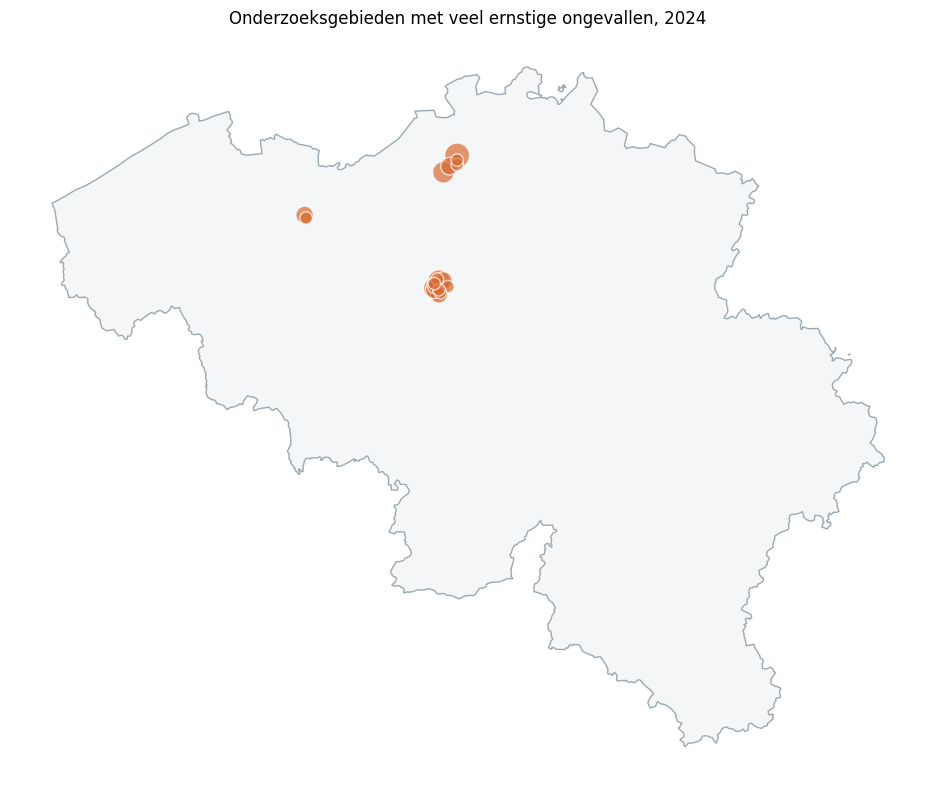

In [6]:
import geopandas as gpd
bad=set(pd.read_csv(T/'geo_uitgesloten.csv',usecols=['_record_id'])._record_id)
located=x[~x._record_id.isin(bad)].copy();located['gx']=(located.MS_X_COORD//500).astype(int);located['gy']=(located.MS_Y_COORD//500).astype(int)
cells=located.groupby(['gx','gy']).agg(ongevallen=('_record_id','count'),ernstig=('ernstig','sum'),gemeente=('TX_MUNTY_COLLISION_NL',lambda s:s.mode().iloc[0] if not s.mode().empty else 'Onbekend'))
cells=cells[cells.ongevallen>=20].copy();cells['ernst_pct']=100*cells.ernstig/cells.ongevallen
cells.sort_values(['ernstig','ongevallen'],ascending=False).to_csv(T/'ernstige_locaties_500m_2024.csv')
display(cells.sort_values(['ernstig','ongevallen'],ascending=False).head(15).round(1))
fig,ax=plt.subplots(figsize=(10,8));country=gpd.read_file(B/'reference_data/belgium_2024.geojson').to_crs(31370);country.plot(ax=ax,color='#F5F6F7',edgecolor='#9BA9B2')
top=cells.sort_values('ernstig',ascending=False).head(20).reset_index();ax.scatter((top.gx+.5)*500,(top.gy+.5)*500,s=top.ernstig*80,color='#D76B32',alpha=.7,edgecolor='white');ax.set(title='Onderzoeksgebieden met veel ernstige ongevallen, 2024');ax.axis('off');fig.tight_layout();fig.savefig(F/'21_ernstige_locaties.png',dpi=200,bbox_inches='tight');fig.savefig(F/'21_ernstige_locaties.svg',bbox_inches='tight');plt.show();plt.close(fig)


## 6. Een concrete locatie nader bekijken
De 500-m-cel met de meeste ernstige ongevallen in 2024 ligt in Antwerpen. We bekijken alle botsingstypen en omstandigheden in die cel, inclusief de lichte ongevallen. Dit levert een onderzoeksvraag op, geen bewijs voor een oorzaak.

In [7]:
top_cell=cells.sort_values(['ernstig','ongevallen'],ascending=False).head(1).reset_index().iloc[0]
case=located[(located.gx==top_cell.gx)&(located.gy==top_cell.gy)].copy()
cols=['_record_id','TX_MUNTY_COLLISION_NL','CD_ROAD_TYPE_NL','TX_COLLISION_TYPE_NL','TX_CROSSWAY_NL','TX_LIGHT_CONDITION_NL','TX_CLASS_ACCIDENTS_NL']
case[cols].to_csv(T/'ernstigste_cel_bronregels_2024.csv',index=False)
for col in cols[2:]:
 print('\n'+col);display(case[col].value_counts(dropna=False).to_frame('ongevallen'))
print('Celcentrum in Lambert 72:',(top_cell.gx+.5)*500,(top_cell.gy+.5)*500)



CD_ROAD_TYPE_NL


,ongevallen
CD_ROAD_TYPE_NL,
Gewestweg,17
Gemeenteweg,12



TX_COLLISION_TYPE_NL


,ongevallen
TX_COLLISION_TYPE_NL,
Met een voetganger,12
Tss. 2 best.: langs opzij (voor-/achterkant-flank),6
Andere of onbekend,3
Tussen 2 bestuurders: Frontale botsing,3
Tussen 2 bestuurders: Flank tegen flank,2
Tussen 2 bestuurders: Langs achteren,2
Kettingbotsing (3 bestuurders of meer),1



TX_CROSSWAY_NL


,ongevallen
TX_CROSSWAY_NL,
Buiten Kruispunt,21
Op Kruispunt,8



TX_LIGHT_CONDITION_NL


,ongevallen
TX_LIGHT_CONDITION_NL,
Dag,19
"Nacht, openbare verlichting aanwezig en ontstoken",6
Dageraad - schemering,3
"Nacht, geen openbare verlichting aanwezig",1



TX_CLASS_ACCIDENTS_NL


,ongevallen
TX_CLASS_ACCIDENTS_NL,
met lichtgewonden,25
met zwaargewonden,4


Celcentrum in Lambert 72: 155250.0 214750.0


## Vervolg voor de presentatie
De hoogste percentages zijn signalen voor gerichte vragen. Controleer per kandidaatlocatie het type botsing, het wegontwerp, zicht, snelheid en verkeersintensiteit. Een ernstig aandeel zonder noemer voor afgelegde kilometers is geen individueel risico. Een kaartcel kan meerdere wegen en kruispunten omvatten; bevestig de locatie voordat je maatregelen aan een weg koppelt.